# Project II: Economic Growth 

This notebook will help you getting started with analyzing the growth dataset, `growth.csv`.

In [106]:
import pandas as pd 
import numpy as np 
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

## Read data 

In [107]:
dat = pd.read_csv('growth.csv')
lbldf = pd.read_csv('labels.csv', index_col='variable')
lbl_all = lbldf.label.to_dict() # as a dictionary
print(f'The data contains {dat.shape[0]} rows (countries) and {dat.shape[1]} columns (variables).')

The data contains 214 rows (countries) and 85 columns (variables).


# Descriptive plots

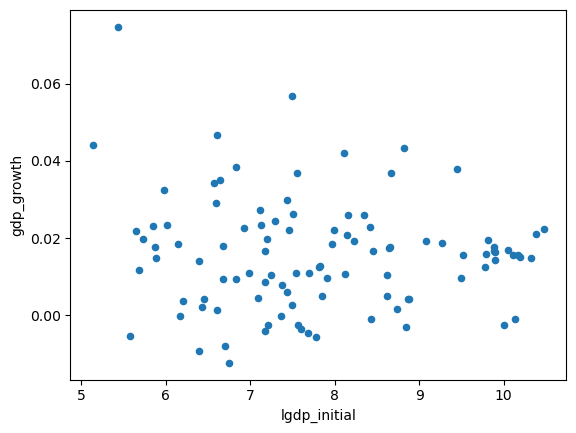

In [108]:
dat.plot.scatter(x='lgdp_initial', y='gdp_growth');

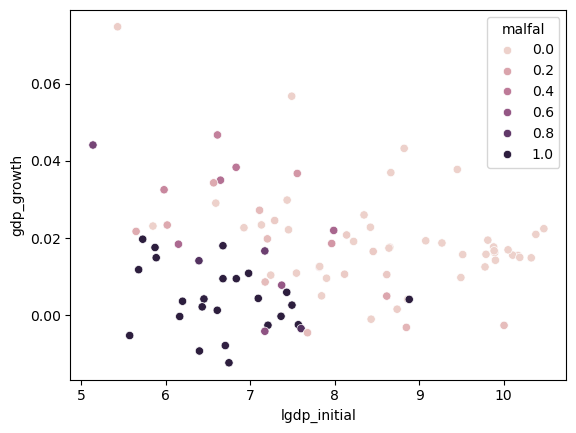

In [109]:
import seaborn as sns 
sns.scatterplot(x='lgdp_initial', y='gdp_growth', data=dat, hue='malfal');

# Collections of variables

In order to make the analysis simpler, it may be convenient to collect variables in sets that belong together naturally. 

In [ ]:
# all other available variables
vv_institutions = ['marketref', 'dem', 'demCGV', 'demBMR', 'demreg'] 
vv_geography = [
        'tropicar','distr', 'distcr', 'distc','suitavg','temp', 'suitgini', 'elevavg', 'elevstd',
        'kgatr', 'precip', 'area', 'abslat', 'cenlong', 'rough','landlock', 
        'africa',  'asia', 'oceania', 'americas' # 'europe' is the reference. We drop area_ar (collinear with area and suitavg).
]
vv_geneticdiversity = ['pdiv', 'pdiv_aa']
vv_historical = ['pd1000', 'pd1500', 'pop1500', 'ln_yst','lpop_initial'] # these are often missing: ['pd1', 'pop1']
vv_religion = ['pprotest', 'pcatholic', 'pmuslim'] #pother is the reference. 
vv_danger = ['yellow', 'malfal',  'uvdamage']
vv_resources = ['oilres', 'goldm', 'iron', 'silv', 'zinc']
vv_educ = ['ls_bl', 'lh_bl'] # secondary, tertiary: we exclude 'lp_bl' (primary) to avoid rank failure 
vv_solow = ['investment_rate', 'pop_growth']

vv_other = ['ginv']


vv_all = {'institutions': vv_institutions, 
          'geography': vv_geography, 
          'geneticdiversity': vv_geneticdiversity,
          'historical': vv_historical,
          'religion': vv_religion,
          'danger':vv_danger, 
          'resources':vv_resources,
          'education': vv_educ,
          'solow': vv_solow,
          'other': vv_other
         }
list_of_lists = vv_all.values()
vv_all['all'] = [v for sublist in list_of_lists for v in sublist]
print(len(vv_all['all']))

52


In [111]:
# convenient to keep a column of ones in the dataset
dat['constant'] = np.ones((dat.shape[0],))

# Simple OLS

In [112]:
# 1. avoiding missings 
I = dat[['gdp_growth', 'lgdp_initial']].notnull().all(axis=1)

# 2. extract dataset 
y = dat.loc[I, 'gdp_growth'].values.reshape((-1,1)) * 100.0
X = dat.loc[I, ['constant','lgdp_initial']].values

# 3. run OLS
betahat = np.linalg.inv(X.T @ X) @ X.T @ y
print(betahat)

[[ 2.24792211]
 [-0.08713416]]


# Adding more controls

In [113]:
vs = vv_all['geography'] + vv_all['religion']
xs = ['lgdp_initial', 'pop_growth', 'investment_rate'] + vs

# avoiding missings
all_vars = ['gdp_growth'] + xs
I = dat[all_vars].notnull().all(1)

# extract data
X = dat.loc[I, xs].values
y = dat.loc[I,'gdp_growth'].values.reshape((-1,1)) * 100. #easier to read output when growth is in 100%

# add const. (unless this breaks the rank condition)
oo = np.ones((I.sum(),1))
X = np.hstack([X, oo])
xs.append('constant') # we put it in as the last element

# check the rank condition
K = X.shape[1]
assert np.linalg.matrix_rank(X) == X.shape[1], f'X does not have full rank'

# compute the OLS estimator
betas = np.linalg.inv(X.T @ X) @ X.T @ y

/var/folders/h9/z9lm5gjn16v18xr3xsl99r800000gn/T/ipykernel_32910/2288867945.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of all will be keyword-only.
  I = dat[all_vars].notnull().all(1)


In [114]:
# format nicely
print(f'Mean y = {y.mean(): 5.2f}% growth per year')
pd.DataFrame({'β': betas[:,0]}, index=xs).round(3)

Mean y =  1.53% growth per year


,β
lgdp_initial,-1.086
pop_growth,9.453
investment_rate,0.066
tropicar,-0.354
distr,-0.000
distcr,0.001
distc,-0.003
suitavg,-0.987
temp,-0.205
suitgini,-0.559


### Descriptive statistics

In [ ]:
#I = dat[['gdp_growth', 'lgdp_initial', 'investment_rate', 'pop_growth', 'ls_bl', 'lp_bl']].notnull().all(axis=1)
#dat_new = dat.loc[I,:]

I = dat[vv_all['all']+['gdp_growth', 'lgdp_initial']].notnull().all(axis=1)
dat_new = dat.loc[I,vv_all['all']+['gdp_growth', 'lgdp_initial']]


with pd.option_context('display.max_rows', None):
    display(dat_new.describe(include='all').T.round(2).sort_values(by='count'))

,count,mean,std,min,25%,50%,75%,max
marketref,65.0,26.55,21.84,0.00,4.76,26.19,42.86,7.337000e+01
americas,65.0,0.25,0.43,0.00,0.00,0.00,0.00,1.000000e+00
pdiv,65.0,0.70,0.06,0.57,0.64,0.73,0.74,7.700000e-01
pdiv_aa,65.0,0.72,0.03,0.63,0.70,0.73,0.74,7.700000e-01
pd1000,65.0,4.14,4.94,0.03,0.65,1.57,7.03,1.987000e+01
pd1500,65.0,7.11,9.21,0.03,1.21,2.62,11.61,3.529000e+01
pop1500,65.0,4859112.60,16516862.58,32454.87,500000.00,900000.00,2000000.00,1.100007e+08
ln_yst,65.0,8.32,0.53,5.99,8.04,8.29,8.61,9.210000e+00
pprotest,65.0,11.05,20.80,0.00,0.40,2.40,11.60,9.780000e+01
pcatholic,65.0,40.12,40.82,0.00,0.70,26.20,90.00,9.690000e+01


In [132]:
corr_matrix = dat_new.drop(columns='constant', errors='ignore').corr(numeric_only=True)

corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ['variable_1', 'variable_2', 'correlation']
high_corr_pairs = corr_pairs.loc[corr_pairs['correlation'].abs() >= 0.94]
high_corr_pairs = high_corr_pairs.sort_values('correlation', key=abs, ascending=False)
display(high_corr_pairs.round(3))

,variable_1,variable_2,correlation
109,demCGV,demBMR,0.950
56,dem,demBMR,0.950
1154,abslat,uvdamage,-0.945


In [117]:
unneccesary_variables = ['']


drop = ['mortality', 'pd1500.1',
        'pop1', 'pop1000',
        'pop1500', 'pdivhmi',
        'population_now','pdivhmi_aa', 
        'capital_growth_pct_gdp_initial']

data_new = dat_new.drop(columns=drop, errors='ignore')
with pd.option_context('display.max_rows', None):
    display(dat_new.describe(include='all').T.round(2).sort_values(by='count'))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mortality,40.0,NaN,NaN,NaN,264.68075,512.186325,8.55,69.575,78.1,197.5,2940.0
leb95,43.0,NaN,NaN,NaN,63.40814,10.862447,37.24,54.015,66.78,71.305,78.98
lt100km,43.0,NaN,NaN,NaN,0.338159,0.320299,0.0,0.096218,0.198958,0.47292,1.0
imr95,43.0,NaN,NaN,NaN,53.395349,36.065839,5.6,30.15,45.6,73.2,170.0
excolony,47.0,NaN,NaN,NaN,0.638298,0.485688,0.0,0.0,1.0,1.0,1.0
imputedmort,48.0,NaN,NaN,NaN,246.35375,470.336126,2.55,70.7,78.2,269.89,2940.0
democ00a,52.0,NaN,NaN,NaN,1.576923,2.899264,0.0,0.0,0.0,1.0,10.0
democ1,52.0,NaN,NaN,NaN,2.634615,3.254131,0.0,0.0,1.0,4.25,10.0
cons00a,53.0,NaN,NaN,NaN,2.188679,2.010134,1.0,1.0,1.0,3.0,7.0
logem4,54.0,NaN,NaN,NaN,4.618333,1.331095,0.936093,4.2359,4.35863,5.622454,7.986165
